# KPI por federación — exploración en Python (Módulo 2, Evaluación 2)

Prototipo de los KPI y de sus gráficos antes de maquetar el dashboard en Power BI / Tableau.

**Datos.** `datos/base_dashboard.csv` (un nado por fila, anonimizado) y `datos/kpi_*_semestre.csv`,
generados por `base_federaciones.py` a partir del ranking mensual 2024 de World Aquatics (v2).

**Dos advertencias que valen para todo el notebook.**
1. La API entrega **la mejor marca de cada nadador por mes**, no todos sus nados. Participaciones
   y podios son **cotas inferiores**.
2. **Sesgo de visibilidad.** Si los torneos nacionales de una federación no llegan al ranking,
   solo se ven sus nadadores de élite compitiendo afuera y sus porcentajes salen inflados. Los
   KPI comparativos se calculan solo sobre federaciones **con torneos locales en el ranking**.

Las marcas mínimas son las de **Beijing 2026, usadas como torneo genérico** (las de 2024 quedan pendientes).

In [1]:
import warnings
warnings.filterwarnings("ignore", module="kaleido")
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go
import plotly.io as pio

pio.renderers.default = "plotly_mimetype+notebook_connected"
pd.set_option("display.width", 200)

DATOS = Path("datos")
b = pd.read_csv(DATOS / "base_dashboard.csv", low_memory=False)
kf = pd.read_csv(DATOS / "kpi_federacion_semestre.csv")
kc = pd.read_csv(DATOS / "kpi_continente_semestre.csv")
torneos = pd.read_csv(DATOS / "torneos.csv")

# Paleta de referencia validada (guía dataviz): orden fijo, el color sigue a la entidad.
AZUL, NARANJA, AGUA, AMARILLO, MAGENTA = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"
GRIS, TINTA, TINTA2 = "#b9b8b3", "#0b0b0b", "#52514e"
COLOR_CONTINENTE = {"Europe": AZUL, "Americas": NARANJA, "Asia": AGUA,
                    "Oceania": AMARILLO, "Africa": MAGENTA}
COLOR_PISCINA = {"LCM": AZUL, "SCM": NARANJA}
NOMBRE_PISCINA = {"LCM": "50 m", "SCM": "25 m"}

plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10, "axes.edgecolor": "#d6d5d0",
    "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#ecebe7", "grid.linestyle": "-", "grid.linewidth": 0.6,
    "axes.titlelocation": "left", "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 11,
})
MIN_NAD = 30          # mínimo de nadadores para mostrar a una federación en un ranking
print(f"{len(b):,} nados · {b.id_nadador.nunique():,} nadadores · {b.federacion.nunique()} federaciones")

436,105 nados · 72,030 nadadores · 210 federaciones


## 0. Calidad del dato: de dónde sale la federación de cada nadador

El 82 % de los nadadores viene inscrito como "Club". La federación se imputa en cascada:
**oficial** (país del participante) → **club** (país del club) → **sede** (país donde compite más).
El nivel *sede* es el menos confiable: conviene mostrarlo como indicador de calidad.

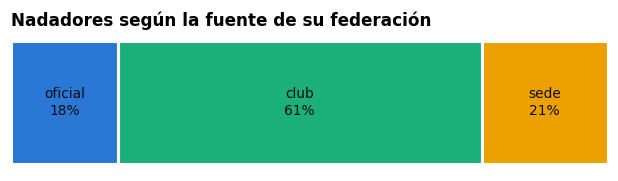

Federaciones con mayor % de nadadores imputados por sede (≥ 30 nadadores):
            nadadores  pct_sede
federacion                     
IRL              1549     0.857
BOL               298     0.826
AUS              4154     0.801
COL               512     0.775
NZL               853     0.770
VIE               296     0.736
BER                87     0.713
USA              3719     0.691
BAR               357     0.681
PAR               574     0.679


In [2]:
nad = b.drop_duplicates("id_nadador")
niveles = nad.nivel_imputacion.value_counts(normalize=True).reindex(["oficial", "club", "sede"])

fig, ax = plt.subplots(figsize=(7, 1.6))
izq = 0
for nivel, color in zip(niveles.index, [AZUL, AGUA, AMARILLO]):
    ax.barh(0, niveles[nivel], left=izq, color=color, height=0.5, edgecolor="white", linewidth=2)
    ax.text(izq + niveles[nivel] / 2, 0, f"{nivel}\n{niveles[nivel]:.0%}", ha="center",
            va="center", fontsize=9, color=TINTA)
    izq += niveles[nivel]
ax.set_xlim(0, 1); ax.set_yticks([]); ax.grid(False); ax.set_xticks([])
for s in ax.spines.values(): s.set_visible(False)
ax.set_title("Nadadores según la fuente de su federación")
plt.show()

q = (nad.groupby("federacion")
        .agg(nadadores=("id_nadador", "size"),
             pct_sede=("nivel_imputacion", lambda s: (s == "sede").mean()))
        .query("nadadores >= @MIN_NAD").sort_values("pct_sede", ascending=False))
print("Federaciones con mayor % de nadadores imputados por sede (≥ 30 nadadores):")
print(q.head(10).round(3).to_string())

## 1. La temporada 2024: cuándo, dónde y qué se compite

Primer acto de la historia: "bajar el balón al suelo" antes de hablar de KPI.

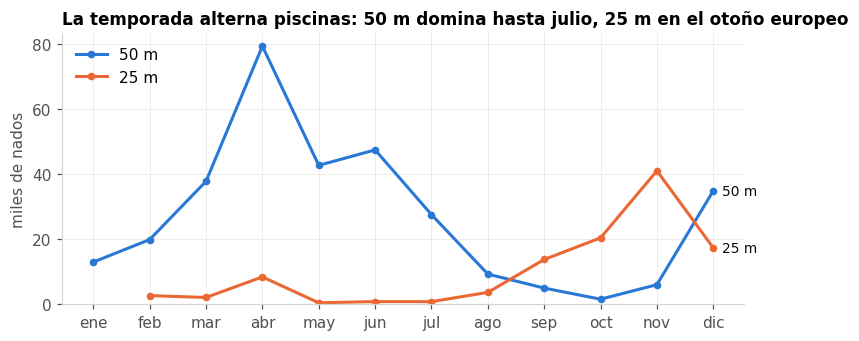

In [3]:
mes = (b.groupby(["mes", "piscina"]).size().unstack())
fig, ax = plt.subplots(figsize=(8, 3.2))
for p in ["LCM", "SCM"]:
    ax.plot(range(12), mes[p].values / 1000, color=COLOR_PISCINA[p], lw=2, marker="o", ms=4)
    ax.annotate(NOMBRE_PISCINA[p], (11, mes[p].values[-1] / 1000), xytext=(6, 0),
                textcoords="offset points", va="center", color=TINTA, fontsize=9)
ax.set_xticks(range(12), ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"])
ax.set_ylabel("miles de nados"); ax.set_ylim(0)
ax.set_title("La temporada alterna piscinas: 50 m domina hasta julio, 25 m en el otoño europeo")
ax.legend([NOMBRE_PISCINA[p] for p in ["LCM", "SCM"]], frameon=False, loc="upper left")
plt.show()

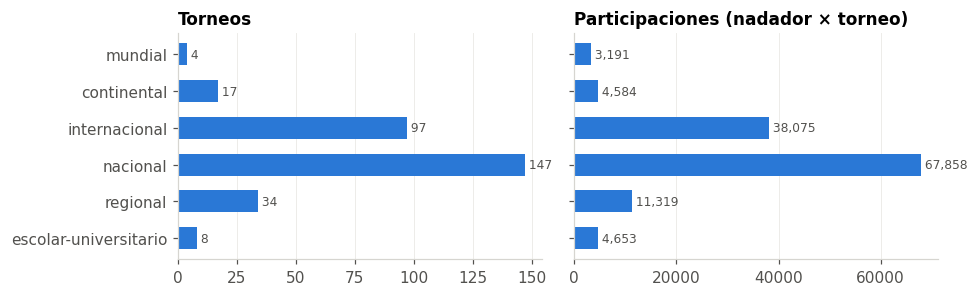

Torneos marcados para revisión manual: 40 de 307


In [4]:
orden = ["mundial", "continental", "internacional", "nacional", "regional", "escolar-universitario"]
t = torneos.groupby("alcance").agg(torneos=("competencia", "size"),
                                    nadadores=("n_nadadores", "sum")).reindex(orden)
fig, axs = plt.subplots(1, 2, figsize=(9, 2.8), sharey=True)
for ax, col, titulo in zip(axs, ["torneos", "nadadores"], ["Torneos", "Participaciones (nadador × torneo)"]):
    ax.barh(t.index[::-1], t[col][::-1], color=AZUL, height=0.6)
    for y, v in enumerate(t[col][::-1]):
        ax.text(v, y, f" {v:,.0f}", va="center", fontsize=8, color=TINTA2)
    ax.set_title(titulo); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()
print(f"Torneos marcados para revisión manual: {int(torneos.revisar.sum())} de {len(torneos)}")

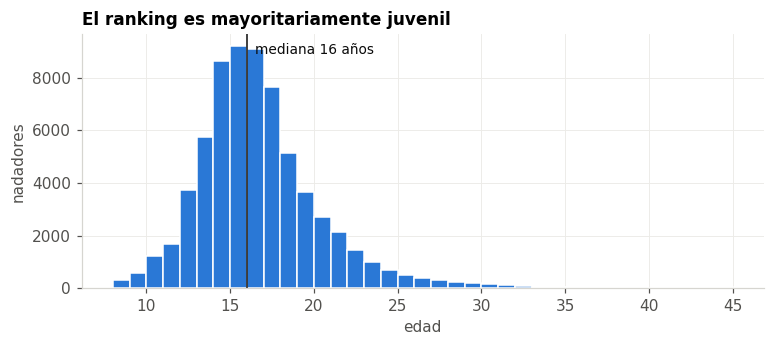

In [5]:
fig, ax = plt.subplots(figsize=(8, 3))
edades = nad.edad.where(nad.edad.between(8, 45))
ax.hist(edades.dropna(), bins=range(8, 46), color=AZUL, edgecolor="white", linewidth=1)
med = edades.median()
ax.axvline(med, color=TINTA, lw=1)
ax.text(med + 0.5, ax.get_ylim()[1] * 0.92, f"mediana {med:.0f} años", fontsize=9, color=TINTA)
ax.set_xlabel("edad"); ax.set_ylabel("nadadores")
ax.set_title("El ranking es mayoritariamente juvenil")
plt.show()

In [6]:
sedes = (b.groupby(["ciudad", "sede_pais_codigo", "sede_lat", "sede_lon"])
           .agg(nadadores=("id_nadador", "nunique"), torneos=("competencia", "nunique"),
                federaciones=("federacion", "nunique"))
           .reset_index())
fig = go.Figure(go.Scattergeo(
    lon=sedes.sede_lon, lat=sedes.sede_lat, mode="markers",
    marker=dict(size=np.sqrt(sedes.nadadores) / 2.2, color=AZUL, opacity=0.6,
                line=dict(color="white", width=1), sizemode="diameter"),
    text=sedes.ciudad + " (" + sedes.sede_pais_codigo + ")<br>" + sedes.nadadores.map("{:,}".format)
         + " nadadores · " + sedes.torneos.astype(str) + " torneos · "
         + sedes.federaciones.astype(str) + " federaciones",
    hoverinfo="text"))
fig.update_geos(projection_type="natural earth", showcountries=True, countrycolor="#d6d5d0",
                showland=True, landcolor="#f4f3f0", showocean=False, showframe=False)
fig.update_layout(title="Dónde se compitió en 2024: 221 sedes, área proporcional a los nadadores",
                  margin=dict(l=0, r=0, t=40, b=0), height=430)
fig.show()
print(sedes.groupby("sede_pais_codigo").nadadores.sum().sort_values(ascending=False).head(8).to_string())

sede_pais_codigo
AUS    7113
JPN    6335
USA    5519
FRA    4865
ITA    4054
ESP    4034
GRE    3896
DEN    3689


## 2. KPI 1 — Eficacia: porcentaje de nadadores con marca mínima

**Nombre (estructura de clase):** *Porcentaje de nadadores de la federación que lograron la marca
mínima B, respecto de sus nadadores rankeados en el semestre.*

`pct_con_minima_B = nadadores con al menos un nado ≤ mínima B / nadadores rankeados` · unidad: % · nivel: propósito.
Mínimas de Beijing 2026 como torneo genérico; cada nado se compara con la mínima de **su** piscina.

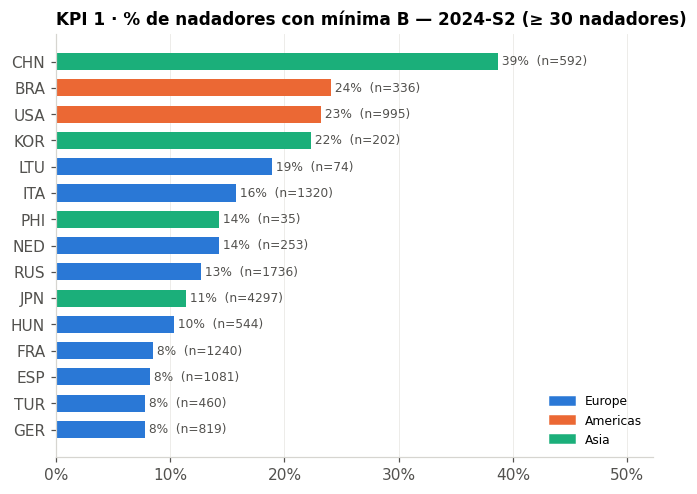

In [7]:
def ranking(kpi, semestre, titulo, formato="{:.0%}", n=15, col_n="nadadores"):
    s = (kf[(kf.semestre == semestre) & (kf.cobertura == "con torneos locales")
            & (kf.nadadores >= MIN_NAD) & (kf[col_n] >= 10)]
         .sort_values(kpi, ascending=False).head(n).iloc[::-1])
    colores = [COLOR_CONTINENTE.get(c, GRIS) for c in s.continente]
    fig, ax = plt.subplots(figsize=(7, 0.28 * len(s) + 0.8))
    ax.barh(s.federacion, s[kpi], color=colores, height=0.65)
    for y, (v, nn) in enumerate(zip(s[kpi], s[col_n])):
        nn = int(nn)
        ax.text(v, y, f" {formato.format(v)}  (n={nn})", va="center", fontsize=8, color=TINTA2)
    ax.grid(axis="y", visible=False); ax.set_title(titulo)
    presentes = [c for c in COLOR_CONTINENTE if c in set(s.continente)]
    ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=COLOR_CONTINENTE[c]) for c in presentes],
              labels=presentes, frameon=False, loc="lower right", fontsize=8)
    ax.set_xlim(0, s[kpi].max() * 1.35)
    if "%" in formato:
        ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
    plt.show()
    return s

_ = ranking("pct_con_minima_B", "2024-S2", "KPI 1 · % de nadadores con mínima B — 2024-S2 (≥ 30 nadadores)")

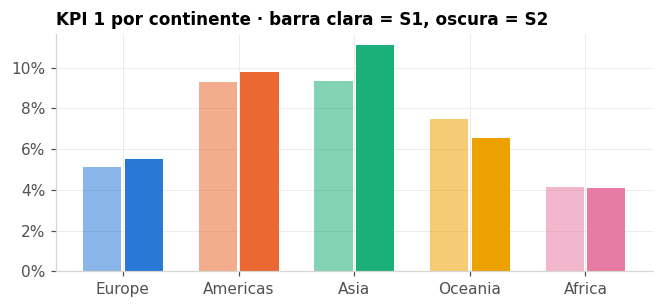

In [8]:
fig, ax = plt.subplots(figsize=(7, 2.8))
conts = ["Europe", "Americas", "Asia", "Oceania", "Africa"]
x = np.arange(len(conts)); w = 0.36
for i, (sem, alpha) in enumerate([("2024-S1", 0.55), ("2024-S2", 1.0)]):
    v = kc.set_index(["continente", "semestre"]).pct_con_minima_B.unstack().loc[conts, sem]
    ax.bar(x + (i - 0.5) * w, v, w * 0.92, color=[COLOR_CONTINENTE[c] for c in conts], alpha=alpha)
ax.set_xticks(x, conts); ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_title("KPI 1 por continente · barra clara = S1, oscura = S2")
plt.show()

### Puente con el Capstone: ¿en qué piscina se logra la mínima?

Si la tabla de mínimas no es equivalente entre piscinas (16 de 24 pruebas son más fáciles en
25 m según el informe), las federaciones que compiten más en piscina corta deberían conseguir
más mínimas allí.

Nadadores con mínima B, por piscina donde la lograron: {'LCM': 3751, 'SCM': 2111}
Proporción de nados por piscina: {'LCM': 0.744, 'SCM': 0.256}


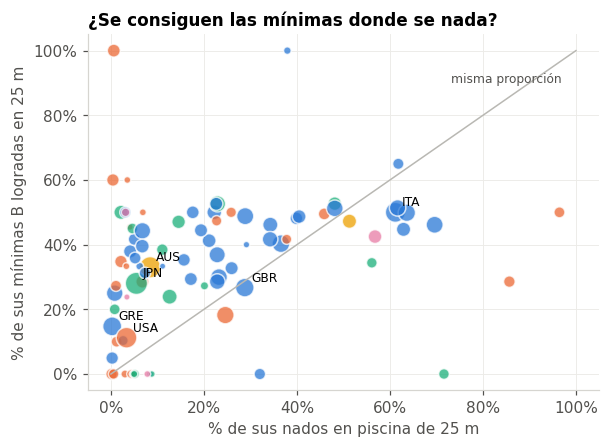

Federaciones: 86 · correlación 0.30


In [9]:
cumple = b[b.cumple_B].drop_duplicates(["id_nadador", "estilo", "distancia", "piscina"])
por_piscina = cumple.groupby("piscina").id_nadador.nunique()
uso = b.groupby("piscina").size() / len(b)
print("Nadadores con mínima B, por piscina donde la lograron:", por_piscina.to_dict())
print("Proporción de nados por piscina:", uso.round(3).to_dict())

f = (b.groupby("federacion").agg(nadadores=("id_nadador", "nunique"),
                                 pct_25=("piscina", lambda s: (s == "SCM").mean()),
                                 continente=("continente", "first"))
       .join(cumple.groupby("federacion").piscina.apply(lambda s: (s == "SCM").mean())
             .rename("pct_minimas_en_25"))
       .query("nadadores >= @MIN_NAD").dropna())
fig, ax = plt.subplots(figsize=(6, 4.2))
ax.scatter(f.pct_25, f.pct_minimas_en_25, s=np.sqrt(f.nadadores) * 3,
           c=[COLOR_CONTINENTE.get(c, GRIS) for c in f.continente], alpha=0.75,
           edgecolor="white", linewidth=1)
ax.plot([0, 1], [0, 1], color=GRIS, lw=1)
ax.text(0.97, 0.9, "misma proporción", ha="right", fontsize=8, color=TINTA2, rotation=0)
for fed, r in f.sort_values("nadadores", ascending=False).head(6).iterrows():
    ax.annotate(fed, (r.pct_25, r.pct_minimas_en_25), xytext=(4, 4), textcoords="offset points", fontsize=8)
ax.set_xlabel("% de sus nados en piscina de 25 m"); ax.set_ylabel("% de sus mínimas B logradas en 25 m")
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}"); ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_title("¿Se consiguen las mínimas donde se nada?")
plt.show()
print(f"Federaciones: {len(f)} · correlación {f.pct_25.corr(f.pct_minimas_en_25):.2f}")

**Lectura.** El 26 % de los nados es en piscina de 25 m, pero ahí se logra el 36 % de las
mínimas B, y la mayoría de las federaciones queda **sobre la diagonal**: consiguen en 25 m una
proporción de mínimas mayor que la proporción de nados que hacen allí. Es coherente con el
hallazgo del informe (16 de 24 pruebas más fáciles en 25 m), pero **no lo prueba**: la temporada
de 25 m incluye los campeonatos de fin de año, donde los nadadores llegan afinados. Es el gancho
narrativo hacia la pregunta del Capstone.

## 3. KPI 2 — Participación en el exterior y distancia

**Nombre:** *Porcentaje de nadadores de la federación que compitieron fuera de su país, respecto de
sus nadadores rankeados en el semestre.* Cota inferior (mejor marca por mes).

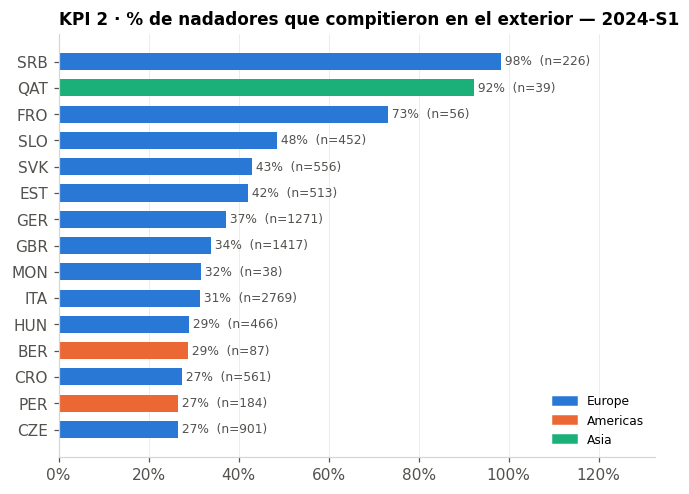

In [10]:
_ = ranking("pct_exterior", "2024-S1", "KPI 2 · % de nadadores que compitieron en el exterior — 2024-S1")

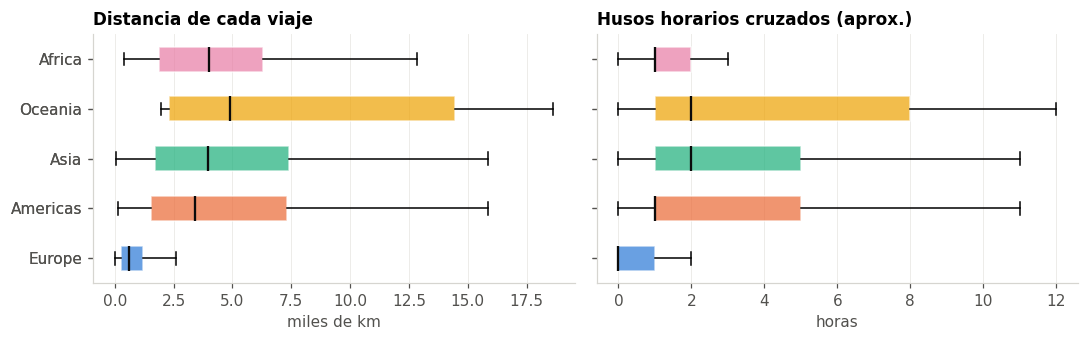

            viajes  km_mediana  husos_mediana
continente                                   
Africa        1343      4005.0            1.0
Americas      3338      3418.0            1.0
Asia          2668      3966.0            2.0
Europe       11964       601.0            0.0
Oceania        609      4890.0            2.0


In [11]:
viajes = b[b.exterior].drop_duplicates(["id_nadador", "competencia"])
fig, axs = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
datos_km = [viajes[viajes.continente == c].km_desde_base.dropna() / 1000 for c in conts]
datos_h = [viajes[viajes.continente == c].husos_aprox.dropna() for c in conts]
for ax, datos, titulo, xl in [(axs[0], datos_km, "Distancia de cada viaje", "miles de km"),
                              (axs[1], datos_h, "Husos horarios cruzados (aprox.)", "horas")]:
    bp = ax.boxplot(datos, vert=False, labels=conts, widths=0.5, patch_artist=True,
                    showfliers=False, medianprops=dict(color=TINTA, lw=1.5))
    for patch, c in zip(bp["boxes"], conts):
        patch.set_facecolor(COLOR_CONTINENTE[c]); patch.set_alpha(0.7); patch.set_edgecolor("white")
    ax.set_title(titulo); ax.set_xlabel(xl); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()
print(viajes.groupby("continente").agg(viajes=("km_desde_base", "size"),
      km_mediana=("km_desde_base", "median"), husos_mediana=("husos_aprox", "median")).to_string())

In [12]:
def mapa_flujos(fed):
    o = b[b.federacion == fed].iloc[0]
    lat0, lon0 = o.lat_base, o.lon_base
    nombre0 = o.ciudad_base if isinstance(o.ciudad_base, str) else "centro del país"
    v = b[(b.federacion == fed) & b.exterior].drop_duplicates(["id_nadador", "competencia"])
    dest = (v.groupby(["ciudad", "sede_pais_codigo", "sede_lat", "sede_lon"])
              .agg(nadadores=("id_nadador", "nunique"), km=("km_desde_base", "first"))
              .reset_index().sort_values("nadadores"))
    fig = go.Figure()
    for r in dest.itertuples():
        fig.add_trace(go.Scattergeo(lon=[lon0, r.sede_lon], lat=[lat0, r.sede_lat], mode="lines",
                                    line=dict(width=0.6 + np.log1p(r.nadadores), color=NARANJA),
                                    opacity=0.55, hoverinfo="skip", showlegend=False))
    fig.add_trace(go.Scattergeo(
        lon=dest.sede_lon, lat=dest.sede_lat, mode="markers",
        marker=dict(size=5 + np.sqrt(dest.nadadores) * 2, color=NARANJA, line=dict(color="white", width=1)),
        text=dest.ciudad + " (" + dest.sede_pais_codigo + "): " + dest.nadadores.astype(str)
             + " nadadores · " + dest.km.map("{:,.0f}".format) + " km",
        hoverinfo="text", showlegend=False))
    fig.add_trace(go.Scattergeo(lon=[lon0], lat=[lat0], mode="markers+text", text=[f"{fed} · {nombre0}"],
                                textposition="bottom center", marker=dict(size=10, color=TINTA),
                                hoverinfo="text", showlegend=False))
    fig.update_geos(projection_type="natural earth", showcountries=True, countrycolor="#d6d5d0",
                    showland=True, landcolor="#f4f3f0", showframe=False)
    fig.update_layout(title=f"{fed}: a dónde viajaron sus nadadores en 2024 "
                            f"({v.id_nadador.nunique()} nadadores, {len(dest)} sedes)",
                      margin=dict(l=0, r=0, t=40, b=0), height=420)
    fig.show()

for fed in ["BRA", "AUS", "ESP"]:
    mapa_flujos(fed)

## 4. KPI 3 — Calidad: podios en torneos internacionales

**Nombre:** *Porcentaje de nadadores de la federación que obtuvieron al menos un podio en torneos
internacionales absolutos, respecto de los que compitieron en ellos en el semestre.*

Se excluyen los internacionales por grupos de edad (Asian Age Group, CARIFTA): reparten medallas
por categoría y un mismo nadador suma muchas, de modo que "podios por nadador" no tenía techo. Torneo internacional = mundial, continental o meeting
internacional **con al menos 10 federaciones** (medido en los datos). El criterio por nombre
solo inflaba los podios del anfitrión: el *Japan Open*, con 3 federaciones, daba a Japón 1,2 podios
por nadador. Entre paréntesis, `n` = nadadores que compitieron en torneos internacionales.

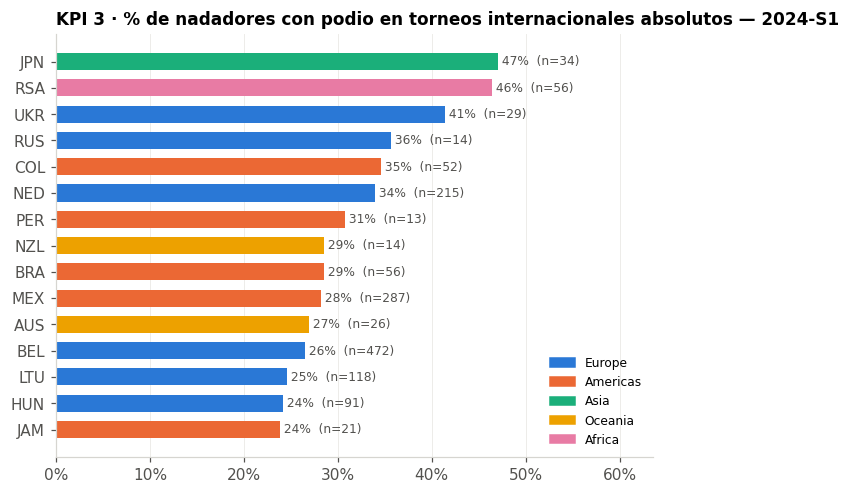

In [13]:
_ = ranking("pct_con_podio_internacional", "2024-S1",
            "KPI 3 · % de nadadores con podio en torneos internacionales absolutos — 2024-S1",
            col_n="compitieron_internacional")

## 5. Resumen de KPI por continente (para las tarjetas del dashboard)

In [14]:
res = kc[["continente", "semestre", "nadadores", "pct_con_minima_B", "pct_exterior",
          "pct_con_podio_internacional", "km_mediana_viaje"]]
res.style.format({"nadadores": "{:,}", "pct_con_minima_B": "{:.1%}", "pct_exterior": "{:.1%}",
                  "pct_con_podio_internacional": "{:.1%}", "km_mediana_viaje": "{:,.0f}"}).hide(axis="index")

continente,semestre,nadadores,pct_con_minima_B,pct_exterior,pct_con_podio_internacional,km_mediana_viaje
Africa,2024-S1,"1,394",4.2%,32.4%,18.0%,"4,268"
Africa,2024-S2,"1,082",4.1%,39.5%,26.4%,"2,844"
Americas,2024-S1,"9,993",9.3%,16.1%,14.4%,"2,782"
Americas,2024-S2,"4,592",9.8%,17.4%,11.7%,"5,709"
Asia,2024-S1,"7,155",9.3%,15.6%,11.2%,"4,037"
Asia,2024-S2,"7,512",11.1%,12.2%,3.1%,"3,907"
Europe,2024-S1,"29,554",5.1%,20.5%,11.4%,566
Europe,2024-S2,"24,870",5.5%,12.9%,13.7%,701
Oceania,2024-S1,"3,347",7.5%,5.6%,17.4%,"4,314"
Oceania,2024-S2,"3,300",6.5%,8.7%,18.0%,"7,112"


## Pendientes antes de fijar los KPI

- **Metas y rangos** de cada KPI (paso 4 de la metodología de clase): sin ellos no hay semáforo.
- **Mínimas 2024** (Doha y París en 50 m, Budapest en 25 m) como contraste de Beijing 2026.
- **Hit rate**: bajar los resultados de los tres campeonatos en sus fechas exactas.
- **Revisión manual** de los 40 torneos marcados en `datos/torneos.csv` → `datos/torneos_override.csv`.
- KPI 3 depende de la clasificación de torneos: un "meeting internacional" con dos federaciones
  infla los podios del anfitrión.